# Entrenamiento del modelo de visión — Tiendita IA (versión DLI corregida)

**Tarea:** clasificar la foto de un producto (6 productos + `fondo`). **Modelo base:** YOLO11n-cls (ImageNet). **GPU:** Tesla T4 (NVIDIA DLI).

Este notebook es autosuficiente: **trae dentro los scripts corregidos** (`%%writefile`), así que no importa qué versión haya en `vision.zip`.

**Archivos que deben estar en `/dli/task`** (ya subidos):
- `raw.zip` — fotos `raw/<sesion>/<clase>/*.jpg`
- `wheels_dli.zip` — paquetes de Python (el DLI no llega a pypi.org)
- `torch-2.5.1+cu121-…whl`, `torchvision-0.20.1+cu121-…whl`, `opencv_python_headless-4.12.0.88-…whl`

**Problemas del entorno DLI resueltos aquí** (registrar en la presentación):
1. Sin acceso a pypi.org → instalación desde wheels subidos a mano.
2. Driver 545 (CUDA ≤ 12.3) → se fija torch 2.5.1+cu121 (otro torch 2.14/cu130 quedó instalado y no corre).
3. Sin `libGL` → OpenCV *headless*.
4. Dos cuDNN instalados (cu12 y cu13) → `CUDNN_STATUS_NOT_INITIALIZED`; se entrena en la T4 con cuDNN desactivado.

## 1. Diagnóstico (no importa torch en este kernel)

In [1]:
import subprocess, sys, os, glob
BASE = "/dli/task"
os.chdir(BASE)
!nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv
def version(mod):
    r = subprocess.run([sys.executable, "-c", f"import {mod}; print({mod}.__version__)"], capture_output=True, text=True)
    return r.stdout.strip() or ("FALTA: " + (r.stderr.strip().splitlines() or ["?"])[-1])
for m in ("torch", "torchvision", "cv2", "ultralytics", "onnx"):
    print(f"{m:<12}", version(m))
print("archivos:", sorted(f for f in os.listdir(BASE) if f.endswith((".zip", ".whl"))))

name, driver_version, memory.total [MiB]
Tesla T4, 545.23.08, 15360 MiB
torch        2.5.1+cu121
torchvision  0.20.1+cu121
cv2          4.12.0
ultralytics  8.3.253
onnx         1.23.2
archivos: ['raw.zip', 'torch-2.5.1+cu121-cp310-cp310-linux_x86_64.whl', 'torchvision-0.20.1+cu121-cp310-cp310-linux_x86_64.whl', 'vision.zip', 'wheels_dli.zip']


## 2. Instalación sin internet
Solo instala lo que falte o esté mal. **Si esta celda instala torch, reinicia el kernel** (Kernel → Restart) y continúa en la sección 3.

In [2]:
import zipfile
reiniciar = False
def pip(*args):
    !{sys.executable} -m pip install -q --no-deps --no-index {" ".join(args)}

# torch 2.5.1+cu121 (el único compatible con el driver 545)
if version("torch") != "2.5.1+cu121":
    whl = sorted(glob.glob(f"{BASE}/**/torch*cu121*.whl", recursive=True))
    assert len(whl) == 2, f"Faltan los .whl de torch/torchvision en {BASE}: {whl}"
    !{sys.executable} -m pip uninstall -y -q torch torchvision
    pip("--force-reinstall", *whl)
    reiniciar = True

# Ultralytics y dependencias (sin resolver deps para no tocar torch)
if not os.path.isdir(f"{BASE}/wheels_dli"):
    zipfile.ZipFile(f"{BASE}/wheels_dli.zip").extractall(BASE)
if version("ultralytics").startswith("FALTA") or version("onnx").startswith("FALTA"):
    pip(*sorted(glob.glob(f"{BASE}/wheels_dli/*.whl")))

# OpenCV sin interfaz gráfica (el DLI no tiene libGL)
if version("cv2").startswith("FALTA"):
    w = glob.glob(f"{BASE}/**/opencv_python_headless-*.whl", recursive=True)
    assert w, "Falta opencv_python_headless-*.whl en /dli/task"
    !{sys.executable} -m pip uninstall -y -q opencv-python opencv-python-headless
    pip("--force-reinstall", w[0])

for m in ("torch", "cv2", "ultralytics", "onnx"):
    print(f"{m:<12}", version(m))
print("\n⚠ REINICIA EL KERNEL y sigue en la sección 3" if reiniciar else "\n✅ Listo, sigue en la sección 3 (sin reiniciar)")

torch        2.5.1+cu121
cv2          4.12.0
ultralytics  8.3.253
onnx         1.23.2

✅ Listo, sigue en la sección 3 (sin reiniciar)


## 3. Preparar carpeta y fotos

In [3]:
import os, zipfile, sys, glob
BASE = "/dli/task"
os.makedirs(f"{BASE}/vision", exist_ok=True)
if not os.path.isdir(f"{BASE}/vision/raw"):
    zipfile.ZipFile(f"{BASE}/raw.zip").extractall(f"{BASE}/vision")
print({s: sorted(os.listdir(f"{BASE}/vision/raw/{s}")) for s in sorted(os.listdir(f"{BASE}/vision/raw"))})

{'s1': ['agua_1l', 'agua_bonafont', 'agua_members_mark', 'chokis', 'coca_cola', 'doritos'], 's2': ['agua_1l', 'agua_bonafont', 'agua_members_mark', 'chokis', 'coca_cola', 'doritos'], 's3': ['agua_1l', 'agua_bonafont', 'agua_members_mark', 'fondo']}


### Scripts corregidos (se escriben encima de los que haya)

In [4]:
%%writefile /dli/task/vision/clases.txt
# Una clase por línea. El ORDEN importa: la línea N (sin contar comentarios) es la clase N-1 en las etiquetas YOLO.
# Origen: docs/catalogo_demo.md (columna clase_vision). La clase "fondo" (sin producto) la agregan los scripts.
# doritos = Nacho y Pizzerola juntos (mismo precio). Videos: sN_doritos.mp4, sN_doritos_2.mp4.
agua_1l
agua_bonafont
agua_members_mark
coca_cola
doritos
chokis

Overwriting /dli/task/vision/clases.txt


In [5]:
%%writefile /dli/task/vision/comun.py
"""Utilidades compartidas: huellas de archivos y datos del entorno para los registros (entregable C)."""
import hashlib
import os
import json
import platform
import subprocess
from datetime import datetime, timezone
from pathlib import Path

AQUI = Path(__file__).resolve().parent

# Plan B para entornos con cuDNN roto (DLI con dos cuDNN instalados): SIN_CUDNN=1 python train.py ...
# Entrena igual en GPU, solo sin cuDNN (más lento). Queda registrado en entorno()["cudnn"].
if os.environ.get("SIN_CUDNN"):
    import torch

    torch.backends.cudnn.enabled = False
ARTEFACTOS = AQUI / "artefactos"


def sha256(ruta: Path) -> str:
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()


def ahora() -> str:
    return datetime.now(timezone.utc).astimezone().isoformat(timespec="seconds")


def entorno() -> dict:
    info = {"python": platform.python_version(), "so": platform.platform()}
    try:
        import torch

        info["torch"] = torch.__version__
        info["cudnn"] = torch.backends.cudnn.version() if torch.backends.cudnn.enabled else "desactivado (SIN_CUDNN)"
        info["cuda"] = torch.version.cuda
        info["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
    except ImportError:
        pass
    try:
        import ultralytics

        info["ultralytics"] = ultralytics.__version__
    except ImportError:
        pass
    try:
        import tensorrt

        info["tensorrt"] = tensorrt.__version__
    except ImportError:
        pass
    try:
        info["nvidia_smi"] = subprocess.run(
            ["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv,noheader"],
            capture_output=True, text=True, timeout=10,
        ).stdout.strip()
    except (OSError, subprocess.SubprocessError):
        pass
    return info


def guardar_json(ruta: Path, datos: dict) -> None:
    ruta.parent.mkdir(parents=True, exist_ok=True)
    ruta.write_text(json.dumps(datos, indent=2, ensure_ascii=False, default=str))
    print(f"Guardado: {ruta}")

Overwriting /dli/task/vision/comun.py


In [6]:
%%writefile /dli/task/vision/split.py
"""Divide las fotos en train/val/test POR SESIÓN (clasificación: una carpeta por clase).

Entrada (lo que genera preparar_videos.py):
    raw/<sesion>/<clase>/*.jpg

Salida (formato de clasificación de Ultralytics):
    dataset/{train,val,test}/<clase>/*.jpg
    dataset/estadisticas.json     (cantidad y distribución -> entregable C y sección 13)

Bases §7: "No deberán colocarse imágenes duplicadas ni versiones de la misma imagen en
conjuntos distintos". Por eso una sesión completa va a un solo conjunto, y además se buscan
fotos casi idénticas entre conjuntos (hash perceptual).

Uso:
    python split.py --train s1,s2 --val s3 --test s4   # 4 sesiones: cada conjunto con las suyas
    python split.py --train s1 --test s2                # 2 sesiones: val sale de train (ver abajo)

Sin --val, la validación se toma del FINAL de cada video de las sesiones de train
(--val-frac, 20 % por defecto) y se descartan --hueco cuadros entre ambos tramos para que no
queden fotos casi iguales a los dos lados. Val solo se usa para elegir la mejor época; la
métrica que se reporta sale de test, que sigue siendo una sesión completa que el modelo no vio.
"""
import argparse
import json
import shutil
import sys
from collections import Counter
from pathlib import Path

from PIL import Image

AQUI = Path(__file__).resolve().parent
EXT_IMG = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
SPLITS = ("train", "val", "test")
FONDO = "fondo"


def leer_clases(ruta: Path) -> list[str]:
    return [l.strip() for l in ruta.read_text().splitlines() if l.strip() and not l.startswith("#")]


def dhash(ruta: Path) -> int:
    """Hash perceptual de 64 bits: resiste cambios de tamaño, compresión y brillo leve."""
    with Image.open(ruta) as im:
        px = im.convert("L").resize((9, 8), Image.Resampling.LANCZOS).tobytes()
    bits = 0
    for fila in range(8):
        for col in range(8):
            bits = (bits << 1) | (px[fila * 9 + col] > px[fila * 9 + col + 1])
    return bits


def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--raw", type=Path, default=AQUI / "raw")
    ap.add_argument("--out", type=Path, default=AQUI / "dataset")
    ap.add_argument("--clases", type=Path, default=AQUI / "clases.txt")
    ap.add_argument("--train", required=True, help="sesiones separadas por coma, ej. s1,s2")
    ap.add_argument("--val", default="", help="sesiones de val; vacío = tramo final de cada video de train")
    ap.add_argument("--test", required=True)
    ap.add_argument("--val-frac", type=float, default=0.2, help="sin --val: fracción final de cada video que va a val")
    ap.add_argument("--hueco", type=int, default=4, help="sin --val: cuadros descartados entre el tramo de train y el de val")
    ap.add_argument("--umbral-dup", type=int, default=4, help="distancia de Hamming máx. para considerar duplicado")
    ap.add_argument("--permitir-dup", action="store_true", help="solo avisar de duplicados entre conjuntos")
    args = ap.parse_args()

    clases = leer_clases(args.clases) + [FONDO]
    asignacion: dict[str, str] = {}
    for split in SPLITS:
        for s in filter(None, getattr(args, split).split(",")):
            if s in asignacion:
                sys.exit(f"ERROR: la sesión {s} está en '{asignacion[s]}' y en '{split}'. Debe ir a un solo conjunto.")
            asignacion[s] = split

    if args.out.exists():
        shutil.rmtree(args.out)
    for split in SPLITS:
        for c in clases:
            (args.out / split / c).mkdir(parents=True)

    val_de_train = not args.val.strip()
    conteo = {s: Counter() for s in SPLITS}
    hashes: dict[str, list[tuple[int, Path]]] = {s: [] for s in SPLITS}
    descartadas_hueco = 0

    def copiar(img: Path, split: str, sesion: str, c: str) -> None:
        shutil.copy2(img, args.out / split / c / f"{sesion}__{img.name}")
        conteo[split][c] += 1
        hashes[split].append((dhash(img), img))

    for sesion, split in asignacion.items():
        dir_ses = args.raw / sesion
        if not dir_ses.is_dir():
            sys.exit(f"ERROR: no existe {dir_ses}")
        extranas = [d.name for d in dir_ses.iterdir() if d.is_dir() and d.name not in clases]
        if extranas:
            sys.exit(f"ERROR: carpetas que no son clases en {dir_ses}: {extranas}. Clases válidas: {clases}")
        for c in clases:
            dir_c = dir_ses / c
            if not dir_c.is_dir():
                continue
            imgs = sorted(p for p in dir_c.iterdir() if p.suffix.lower() in EXT_IMG)
            if not (val_de_train and split == "train"):
                for img in imgs:
                    copiar(img, split, sesion, c)
                continue
            # Agrupar por video (nombre antes de "_fNNNNN") y cortar cada uno en el tiempo.
            por_video: dict[str, list[Path]] = {}
            for img in imgs:
                por_video.setdefault(img.stem.rsplit("_f", 1)[0], []).append(img)
            for cuadros in por_video.values():
                n_val = round(len(cuadros) * args.val_frac)
                corte = len(cuadros) - n_val
                for img in cuadros[:max(0, corte - args.hueco)]:
                    copiar(img, "train", sesion, c)
                for img in cuadros[corte:]:
                    copiar(img, "val", sesion, c)
                descartadas_hueco += min(args.hueco, corte)

    # Sin --val, val y train salen del mismo video: si el producto estuvo quieto, hay cuadros
    # casi iguales a los dos lados. Esos se quitan de val (no se aborta: es esperable).
    quitadas_val = 0
    if val_de_train:
        h_train = [h for h, _ in hashes["train"]]
        quedan = []
        for hv, pv in hashes["val"]:
            if any(bin(hv ^ ht).count("1") <= args.umbral_dup for ht in h_train):
                (args.out / "val" / pv.parent.name / f"{pv.parent.parent.name}__{pv.name}").unlink()
                conteo["val"][pv.parent.name] -= 1
                quitadas_val += 1
            else:
                quedan.append((hv, pv))
        hashes["val"] = quedan
        if quitadas_val:
            print(f"Quitadas {quitadas_val} fotos de val casi iguales a otras de train (mismo video).")

    # Duplicados casi idénticos entre conjuntos distintos
    dups = []
    for a_i, a in enumerate(SPLITS):
        for b in SPLITS[a_i + 1:]:
            for ha, pa in hashes[a]:
                for hb, pb in hashes[b]:
                    if bin(ha ^ hb).count("1") <= args.umbral_dup:
                        dups.append((a, pa, b, pb))
    if dups:
        print(f"\n⚠ {len(dups)} posibles duplicados entre conjuntos distintos:")
        for a, pa, b, pb in dups[:30]:
            print(f"  [{a}] {pa}  ~  [{b}] {pb}")
        if not args.permitir_dup:
            shutil.rmtree(args.out)  # no dejar un dataset a medias que train.py pueda usar por error
            sys.exit("Quita esas fotos de una de las sesiones (o revísalas a mano y usa --permitir-dup).")

    stats = {
        "tarea": "clasificación de imágenes (un producto por foto)",
        "sesiones": asignacion,
        "validacion": (
            f"último {args.val_frac:.0%} de cada video de las sesiones de train; "
            f"{descartadas_hueco} cuadros descartados como hueco ({args.hueco} por video); "
            f"{quitadas_val} fotos de val quitadas por ser casi iguales a una de train"
            if val_de_train else "sesiones propias"
        ),
        "imagenes_por_conjunto": {s: sum(conteo[s].values()) for s in SPLITS},
        "imagenes_por_clase": {s: {c: conteo[s].get(c, 0) for c in clases} for s in SPLITS},
        "duplicados_entre_conjuntos": len(dups),
        "origen": "cuadros extraídos de videos grabados por el equipo (preparar_videos.py)",
    }
    (args.out / "estadisticas.json").write_text(json.dumps(stats, indent=2, ensure_ascii=False))

    print(f"\n{'clase':<22}{'train':>7}{'val':>7}{'test':>7}")
    for c in clases:
        fila = [conteo[s].get(c, 0) for s in SPLITS]
        aviso = "  ⚠ sin fotos en algún conjunto" if 0 in fila else ""
        print(f"{c:<22}{fila[0]:>7}{fila[1]:>7}{fila[2]:>7}{aviso}")
    print(f"{'TOTAL':<22}" + "".join(f"{sum(conteo[s].values()):>7}" for s in SPLITS))
    print(f"\nListo: {args.out}")


if __name__ == "__main__":
    main()

Overwriting /dli/task/vision/split.py


In [7]:
%%writefile /dli/task/vision/train.py
"""Ajuste fino (transfer learning) de YOLO11n-cls preentrenado en ImageNet a los productos de la tiendita.

Guarda en artefactos/<nombre>/:
    best.pt                  pesos entrenados (los que usa la app)
    registro.json            fecha, duración, GPU, versiones, parámetros, épocas, SHA-256  -> entregable C
    estadisticas_datos.json  cantidad y distribución de las fotos
    resultados/              curvas, results.csv y args.yaml de Ultralytics

Uso:
    python train.py --nombre humo --epochs 2   # prueba rápida antes de gastar GPU
    python train.py --nombre v1                # entrenamiento completo (~5-15 min en T4)
"""
import argparse
import shutil
import time
from pathlib import Path

from comun import AQUI, ARTEFACTOS, ahora, entorno, guardar_json, sha256

MODELO_BASE = {
    "nombre": "YOLO11n-cls (clasificación)",
    "archivo": "yolo11n-cls.pt",
    "procedencia": "Ultralytics, preentrenado en ImageNet-1k (1000 clases) — https://docs.ultralytics.com/tasks/classify/",
    "licencia": "AGPL-3.0",
}


def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--data", type=Path, default=AQUI / "dataset", help="carpeta con train/ val/ test/")
    ap.add_argument("--modelo", default=MODELO_BASE["archivo"])
    ap.add_argument("--nombre", required=True, help="versión del modelo, ej. v1")
    ap.add_argument("--epochs", type=int, default=30)
    ap.add_argument("--imgsz", type=int, default=224)
    ap.add_argument("--batch", type=int, default=64, help="64 cabe holgado en una T4 de 16 GB a 224 px")
    ap.add_argument("--patience", type=int, default=10, help="corta si val no mejora en N épocas")
    ap.add_argument("--seed", type=int, default=0)
    args = ap.parse_args()

    from ultralytics import YOLO

    destino = ARTEFACTOS / args.nombre
    if destino.exists():
        raise SystemExit(f"{destino} ya existe: usa otro --nombre para no sobrescribir evidencia.")
    if not (args.data / "estadisticas.json").exists():
        raise SystemExit(f"{args.data} está incompleto o no existe: corre split.py primero (y que termine sin errores).")

    # En clasificación, con auto_augment (RandAugment, el valor por defecto) Ultralytics IGNORA hsv_*:
    # se apaga para que el ajuste de tono/saturación/brillo sí se aplique (las sesiones difieren en
    # balance de blancos). Probado: con RandAugment los pesos salían idénticos al cambiar hsv_*.
    aumentos = {"fliplr": 0.5, "flipud": 0.0, "hsv_h": 0.04, "hsv_s": 0.7, "hsv_v": 0.5, "erasing": 0.3,
                "auto_augment": None}
    inicio, t0 = ahora(), time.time()
    modelo = YOLO(args.modelo)
    modelo.train(
        data=str(args.data),
        epochs=args.epochs,
        imgsz=args.imgsz,
        batch=args.batch,
        patience=args.patience,
        seed=args.seed,
        deterministic=True,
        project=str(AQUI / "runs"),
        name=args.nombre,
        plots=True,
        # La luz y que la mano tape parte del producto varían mucho en la tienda; voltear de cabeza no aporta.
        **aumentos,
    )
    fin, duracion = ahora(), time.time() - t0

    trainer = modelo.trainer
    destino.mkdir(parents=True)
    best = destino / "best.pt"
    shutil.copy2(trainer.best, best)
    shutil.copytree(trainer.save_dir, destino / "resultados")
    shutil.copy2(args.data / "estadisticas.json", destino / "estadisticas_datos.json")

    guardar_json(destino / "registro.json", {
        "tarea": "clasificación de imágenes",
        "modelo_base": MODELO_BASE | {"archivo": args.modelo},
        "datos": str(args.data),
        "clases": list(modelo.names.values()) if isinstance(modelo.names, dict) else modelo.names,
        "parametros": vars(args) | aumentos,
        "inicio": inicio,
        "fin": fin,
        "duracion_min": round(duracion / 60, 1),
        "epocas_ejecutadas": trainer.epoch + 1,
        "mejor_fitness_val": float(trainer.best_fitness) if trainer.best_fitness is not None else None,
        "entorno": entorno(),
        "artefacto": {"ruta": str(best.relative_to(AQUI)), "sha256": sha256(best)},
    })
    print(f"\nListo en {duracion / 60:.1f} min. Siguiente: python eval.py --nombre {args.nombre}")


if __name__ == "__main__":
    main()

Overwriting /dli/task/vision/train.py


In [8]:
%%writefile /dli/task/vision/eval.py
"""Evaluación con el conjunto de PRUEBA reservado (bases §7 y §13).

Produce en artefactos/<nombre>/eval/:
    metricas.json    exactitud top-1/top-5, precisión y exhaustividad por clase, matriz de confusión,
                     efecto del umbral de confianza y comparación con el modelo base
    val_test/        matriz de confusión (imagen) de Ultralytics
    aciertos/        ejemplos bien clasificados
    errores/         ejemplos mal clasificados (el nombre dice real -> predicho)

Cómo se calcula (para explicarlo al jurado):
  - Exactitud top-1 = fotos de test cuya clase más probable es la correcta / total de fotos de test.
  - Precisión de una clase = de las fotos que el modelo dijo "X", cuántas eran X.
  - Exhaustividad de una clase = de las fotos que eran X, cuántas reconoció como X.
  - Umbral de confianza: si la probabilidad es menor, la app pide al usuario confirmar el producto.

Uso:
    python eval.py --nombre v1
"""
import argparse
import shutil
from collections import Counter, defaultdict
from pathlib import Path

from comun import AQUI, ARTEFACTOS, ahora, guardar_json

EXT_IMG = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}


def imagenes_test(data: Path) -> list[tuple[Path, str]]:
    return [
        (img, d.name)
        for d in sorted((data / "test").iterdir()) if d.is_dir()
        for img in sorted(d.iterdir()) if img.suffix.lower() in EXT_IMG
    ]


def predecir(modelo, muestras, lote: int = 32):
    """Predice en lotes: pasar la lista completa a predict() la mete en UN solo batch (sin memoria en GPU)."""
    for i in range(0, len(muestras), lote):
        yield from modelo.predict([str(p) for p, _ in muestras[i:i + lote]], imgsz=224, verbose=False)


def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--nombre", required=True)
    ap.add_argument("--data", type=Path, default=AQUI / "dataset")
    ap.add_argument("--umbral", type=float, default=0.6, help="confianza mínima para aceptar sin pedir confirmación")
    ap.add_argument("--ejemplos", type=int, default=12, help="máx. imágenes por carpeta aciertos/errores")
    args = ap.parse_args()

    from ultralytics import YOLO

    base = ARTEFACTOS / args.nombre
    salida = base / "eval"
    if salida.exists():
        shutil.rmtree(salida)
    modelo = YOLO(str(base / "best.pt"))
    nombres = modelo.names

    # 1) Métrica oficial de Ultralytics sobre test (+ imagen de la matriz de confusión)
    # Ultralytics 8.3 se niega si test tiene menos clases que train (p. ej. sin fotos de "fondo"):
    # en ese caso top-1/top-5 se calculan abajo, foto por foto, con el mismo modelo.
    try:
        r = modelo.val(data=str(args.data), split="test", project=str(salida), name="val_test", plots=True)
        top1, top5 = float(r.top1), float(r.top5)
    except Exception as ex:  # noqa: BLE001
        print(f"⚠ modelo.val(split='test') falló ({ex}); se calcula la exactitud foto por foto.")
        top1 = top5 = None

    # 2) Predicción foto por foto: matriz de confusión, métricas por clase, ejemplos
    muestras = imagenes_test(args.data)
    (salida / "aciertos").mkdir(parents=True, exist_ok=True)
    (salida / "errores").mkdir(parents=True, exist_ok=True)
    matriz: dict[str, Counter] = defaultdict(Counter)
    confianzas = []  # (confianza, acierto)
    n_ok = n_err = n_top5 = 0
    for (img, real), res in zip(muestras, predecir(modelo, muestras)):
        pred = nombres[int(res.probs.top1)]
        conf = float(res.probs.top1conf)
        matriz[real][pred] += 1
        n_top5 += real in [nombres[int(i)] for i in res.probs.top5]
        confianzas.append((conf, pred == real))
        if pred == real:
            n_ok += 1
            if n_ok <= args.ejemplos:
                res.save(filename=str(salida / "aciertos" / img.name))
        else:
            n_err += 1
            if n_err <= args.ejemplos:
                res.save(filename=str(salida / "errores" / f"{real}__como__{pred}__{conf:.2f}__{img.name}"))

    if top1 is None:
        top1, top5 = n_ok / len(muestras), n_top5 / len(muestras)
    clases = list(nombres.values())
    por_clase = {}
    for c in clases:
        tp = matriz[c][c]
        reales = sum(matriz[c].values())
        predichas = sum(matriz[x][c] for x in clases)
        por_clase[c] = {
            "fotos_test": reales,
            "precision": round(tp / predichas, 4) if predichas else None,
            "exhaustividad": round(tp / reales, 4) if reales else None,
        }
    confusiones = Counter({f"{r_} -> {p}": n for r_ in clases for p, n in matriz[r_].items() if p != r_})

    seguras = [ok for conf, ok in confianzas if conf >= args.umbral]
    umbral = {
        "umbral": args.umbral,
        "fotos_aceptadas_sin_confirmar": f"{len(seguras)}/{len(confianzas)}",
        "exactitud_en_aceptadas": round(sum(seguras) / len(seguras), 4) if seguras else None,
        "fotos_que_piden_confirmacion": len(confianzas) - len(seguras),
    }

    # 3) Comparación con el modelo base (bases §13): ImageNet no tiene estos productos
    base_in = YOLO("yolo11n-cls.pt")
    vistas: dict[str, Counter] = defaultdict(Counter)
    for (img, real), res in zip(muestras, predecir(base_in, muestras)):
        vistas[real][base_in.names[int(res.probs.top1)]] += 1

    guardar_json(salida / "metricas.json", {
        "fecha": ahora(),
        "conjunto": "test (sesiones reservadas, no usadas en entrenamiento ni validación)",
        "fotos_test": len(muestras),
        "global": {"exactitud_top1": round(top1, 4), "exactitud_top5": round(top5, 4)},
        "por_clase": por_clase,
        "matriz_confusion": {c: dict(matriz[c]) for c in clases},
        "confusiones_mas_frecuentes": dict(confusiones.most_common(10)),
        "umbral_de_confianza": umbral,
        "comparacion_modelo_base": {
            "modelo": "yolo11n-cls.pt (ImageNet-1k, sin ajustar)",
            "comparable": False,
            "motivo": (
                "El modelo base clasifica en 1000 categorías genéricas de ImageNet (p. ej. 'pop bottle', "
                "'water bottle', 'packet'); no tiene nuestros productos, así que su exactitud sobre nuestras "
                "clases es 0 por definición. Se reporta qué categoría genérica asigna a cada producto para "
                "mostrar que, sin ajuste fino, no distingue productos con distinto precio."
            ),
            "prediccion_base_por_producto": {c: dict(vistas[c].most_common(3)) for c in clases},
        },
    })
    print(f"\nExactitud top-1 = {top1:.3f}   top-5 = {top5:.3f}")
    print(f"Con umbral {args.umbral}: {umbral['fotos_aceptadas_sin_confirmar']} aceptadas, "
          f"exactitud en ellas = {umbral['exactitud_en_aceptadas']}")
    if confusiones:
        print("Confusiones más frecuentes:", dict(confusiones.most_common(3)))
    print(f"Siguiente: python export_trt.py --nombre {args.nombre}")


if __name__ == "__main__":
    main()

Overwriting /dli/task/vision/eval.py


## 4. GPU y cuDNN
cuDNN se **desactiva** en este kernel (está roto en el DLI). El entrenamiento sigue en la T4.

In [9]:
import os, sys, runpy, torch
os.chdir("/dli/task/vision")
sys.path.insert(0, "/dli/task/vision")
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0))
print("cuDNN instalado:", torch.backends.cudnn.version())
torch.backends.cudnn.enabled = False
os.environ["SIN_CUDNN"] = "1"   # comun.py lo registra en registro.json
x = torch.randn(1, 3, 224, 224, device="cuda")
print("conv en GPU OK:", torch.nn.functional.conv2d(x, torch.randn(8, 3, 3, 3, device="cuda")).shape)

def correr(script, *args):
    """Corre un script en ESTE proceso (hereda cuDNN desactivado)."""
    sys.argv = [script, *map(str, args)]
    runpy.run_path(script, run_name="__main__")

torch 2.5.1+cu121 | CUDA: True | Tesla T4
cuDNN instalado: 92400
conv en GPU OK: torch.Size([1, 8, 222, 222])


## 5. División train / val / test por sesión
s1 y s3 entrenan (val = último 20 % de cada video); **s2 completa es la prueba**.

In [10]:
correr("split.py", "--train", "s1,s3", "--test", "s2")


clase                   train    val   test
agua_1l                   188     48    117
agua_bonafont             133     35    110
agua_members_mark         162     43    118
coca_cola                  93     24     95
doritos                   116     31    241
chokis                     93     24    120
fondo                      10      3      0  ⚠ sin fotos en algún conjunto
TOTAL                     795    208    801

Listo: /dli/task/vision/dataset


## 6. Prueba de humo (2 épocas)

In [16]:
for f, a, b in [("train.py", "        plots=True,\n", "        plots=True,\n        workers=0,\n"),
                ("eval.py", 'plots=True)', 'plots=True, workers=0)')]:
    s = open(f).read()
    if "workers=0" not in s:
        open(f, "w").write(s.replace(a, b, 1))
    print(f, "workers=0" in open(f).read())

train.py True
eval.py True


In [17]:
import shutil
for d in ("artefactos/humo_dli", "runs/humo_dli"):
    shutil.rmtree(d, ignore_errors=True)
correr("train.py", "--nombre", "humo_dli", "--epochs", 2)

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.253 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14930MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=None, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/dli/task/vision/dataset, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.3, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.04, hsv_s=0.7, hsv_v=0.5, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=humo_dli, nbs=64, nms=False, opset=None, opti

/usr/local/lib/python3.10/dist-packages/torch/nn/modules/conv.py:549: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:208.)
  return F.conv2d(
/usr/local/lib/python3.10/dist-packages/ultralytics/nn/modules/block.py:1300: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >=

AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1301.6±416.9 MB/s, size: 31.1 KB)
train: Scanning /dli/task/vision/dataset/train... 795 images, 0 corrupt: 100% ━━━━━━━━━━━━ 795/795 185.2Mit/s 0.0s
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1838.4±343.7 MB/s, size: 48.1 KB)
val: Scanning /dli/task/vision/dataset/val... 208 images, 0 corrupt: 100% ━━━━━━━━━━━━ 208/208 51.3Mit/s 0.0s
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.000909, momentum=0.9) with parameter groups 39 weight(decay=0.0), 40 weight(decay=0.0005), 40 bias(decay=0.0)
Image sizes 224 train, 224 val
Using 0 dataloader workers
Logging results to /dli/task/vision/runs/humo_dli
Starting training for 2 epochs...

      Epoch    GPU_mem       loss  Instances       Size


/usr/local/lib/python3.10/dist-packages/torch/nn/modules/conv.py:549: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:208.)
  return F.conv2d(
/usr/local/lib/python3.10/dist-packages/ultralytics/nn/modules/block.py:1300: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >=

        1/2      0.66G      2.203         64        224: 0% ──────────── 0/13  1.5s

/usr/local/lib/python3.10/dist-packages/torch/autograd/graph.py:825: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:208.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        1/2     0.705G      1.902         27        224: 100% ━━━━━━━━━━━━ 13/13 1.5s/it 19.6s1.1s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 2/2 1.0it/s 2.0s4.0s
                   all      0.462      0.952

      Epoch    GPU_mem       loss  Instances       Size


/usr/local/lib/python3.10/dist-packages/torch/nn/modules/conv.py:549: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:208.)
  return F.conv2d(
/usr/local/lib/python3.10/dist-packages/ultralytics/nn/modules/block.py:1300: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >=

        2/2     0.826G      1.454         64        224: 0% ──────────── 0/13  1.5s

/usr/local/lib/python3.10/dist-packages/torch/autograd/graph.py:825: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:208.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        2/2     0.826G      1.157         27        224: 100% ━━━━━━━━━━━━ 13/13 1.4s/it 18.5s1.2s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 2/2 1.0it/s 2.0s4.0s
                   all      0.774      0.995

2 epochs completed in 0.012 hours.
Optimizer stripped from /dli/task/vision/runs/humo_dli/weights/last.pt, 3.2MB
Optimizer stripped from /dli/task/vision/runs/humo_dli/weights/best.pt, 3.2MB

Validating /dli/task/vision/runs/humo_dli/weights/best.pt...
Ultralytics 8.3.253 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14930MiB)
YOLO11n-cls summary (fused): 47 layers, 1,534,991 parameters, 0 gradients, 3.2 GFLOPs
train: /dli/task/vision/dataset/train... found 795 images in 7 classes ✅ 
val: /dli/task/vision/dataset/val... found 208 images in 7 classes ✅ 
ERROR ❌ test: /dli/task/vision/dataset/test... found 801 images in 6 classes (requires 7 classes, not 6)
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 2/2 1.1s/it 2.1s4.0s
              

## 7. Entrenamiento completo (30 épocas)

In [19]:
for d in ("artefactos/v1", "runs/v1"):
    shutil.rmtree(d, ignore_errors=True)
correr("train.py", "--nombre", "v1", "--epochs", 30)

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.253 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14930MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=None, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/dli/task/vision/dataset, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.3, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.04, hsv_s=0.7, hsv_v=0.5, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=v1, nbs=64, nms=False, opset=None, optimize=

/usr/local/lib/python3.10/dist-packages/torch/nn/modules/conv.py:549: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:208.)
  return F.conv2d(
/usr/local/lib/python3.10/dist-packages/ultralytics/nn/modules/block.py:1300: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >=

AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1209.7±367.0 MB/s, size: 31.1 KB)
train: Scanning /dli/task/vision/dataset/train... 795 images, 0 corrupt: 100% ━━━━━━━━━━━━ 795/795 151.6Mit/s 0.0s
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1546.9±498.4 MB/s, size: 48.1 KB)
val: Scanning /dli/task/vision/dataset/val... 208 images, 0 corrupt: 100% ━━━━━━━━━━━━ 208/208 58.2Mit/s 0.0s
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.000909, momentum=0.9) with parameter groups 39 weight(decay=0.0), 40 weight(decay=0.0005), 40 bias(decay=0.0)
Image sizes 224 train, 224 val
Using 0 dataloader workers
Logging results to /dli/task/vision/runs/v1
Starting training for 30 epochs...

      Epoch    GPU_mem       loss  Instances       Size


/usr/local/lib/python3.10/dist-packages/torch/nn/modules/conv.py:549: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:208.)
  return F.conv2d(
/usr/local/lib/python3.10/dist-packages/ultralytics/nn/modules/block.py:1300: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >=

       1/30     0.678G      2.203         64        224: 0% ──────────── 0/13  1.8s

/usr/local/lib/python3.10/dist-packages/torch/autograd/graph.py:825: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:208.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (45 outputs left out)

/usr/local/lib/python3.10/dist-packages/torch/nn/modules/conv.py:549: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:208.)
  return F.conv2d(
/usr/local/lib/python3.10/dist-packages/ultralytics/nn/modules/block.py:1300: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >=

      13/30     0.844G    0.01245         64        224: 0% ──────────── 0/13  1.4s

/usr/local/lib/python3.10/dist-packages/torch/autograd/graph.py:825: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:208.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      13/30     0.844G    0.03478         27        224: 100% ━━━━━━━━━━━━ 13/13 1.4s/it 17.7s1.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 2/2 1.0it/s 1.9s3.9s
                   all          1          1
EarlyStopping: Training stopped early as no improvement observed in last 10 epochs. Best results observed at epoch 3, best model saved as best.pt.
To update EarlyStopping(patience=10) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

13 epochs completed in 0.074 hours.
Optimizer stripped from /dli/task/vision/runs/v1/weights/last.pt, 3.2MB
Optimizer stripped from /dli/task/vision/runs/v1/weights/best.pt, 3.2MB

Validating /dli/task/vision/runs/v1/weights/best.pt...
Ultralytics 8.3.253 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14930MiB)
YOLO11n-cls summary (fused): 47 layers, 1,534,991 parameters, 0 gradients, 3.2 GFLOPs
train: /dli/task/vision/dataset/train... found 795 images in 7 classes ✅ 
val: /dli/task

## 8. Evaluación con el conjunto de prueba (s2)

In [20]:
correr("eval.py", "--nombre", "v1")

Ultralytics 8.3.253 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14930MiB)
YOLO11n-cls summary (fused): 47 layers, 1,534,991 parameters, 0 gradients, 3.2 GFLOPs
train: /dli/task/vision/dataset/train... found 795 images in 7 classes ✅ 
val: /dli/task/vision/dataset/val... found 208 images in 7 classes ✅ 
ERROR ❌ test: /dli/task/vision/dataset/test... found 801 images in 6 classes (requires 7 classes, not 6)
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1161.9±299.8 MB/s, size: 31.2 KB)
test: Scanning /dli/task/vision/dataset/test... 801 images, 0 corrupt: 100% ━━━━━━━━━━━━ 801/801 3.9Kit/s 0.2s0.0s
test: New cache created: /dli/task/vision/dataset/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 51/51 7.0it/s 7.3s0.1s
                   all      0.953          1
Speed: 0.1ms preprocess, 4.4ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /dli/task/vision/artefactos/v1/eval/val_test
Guardado: /dli/task/vision/artefactos/v1/eval

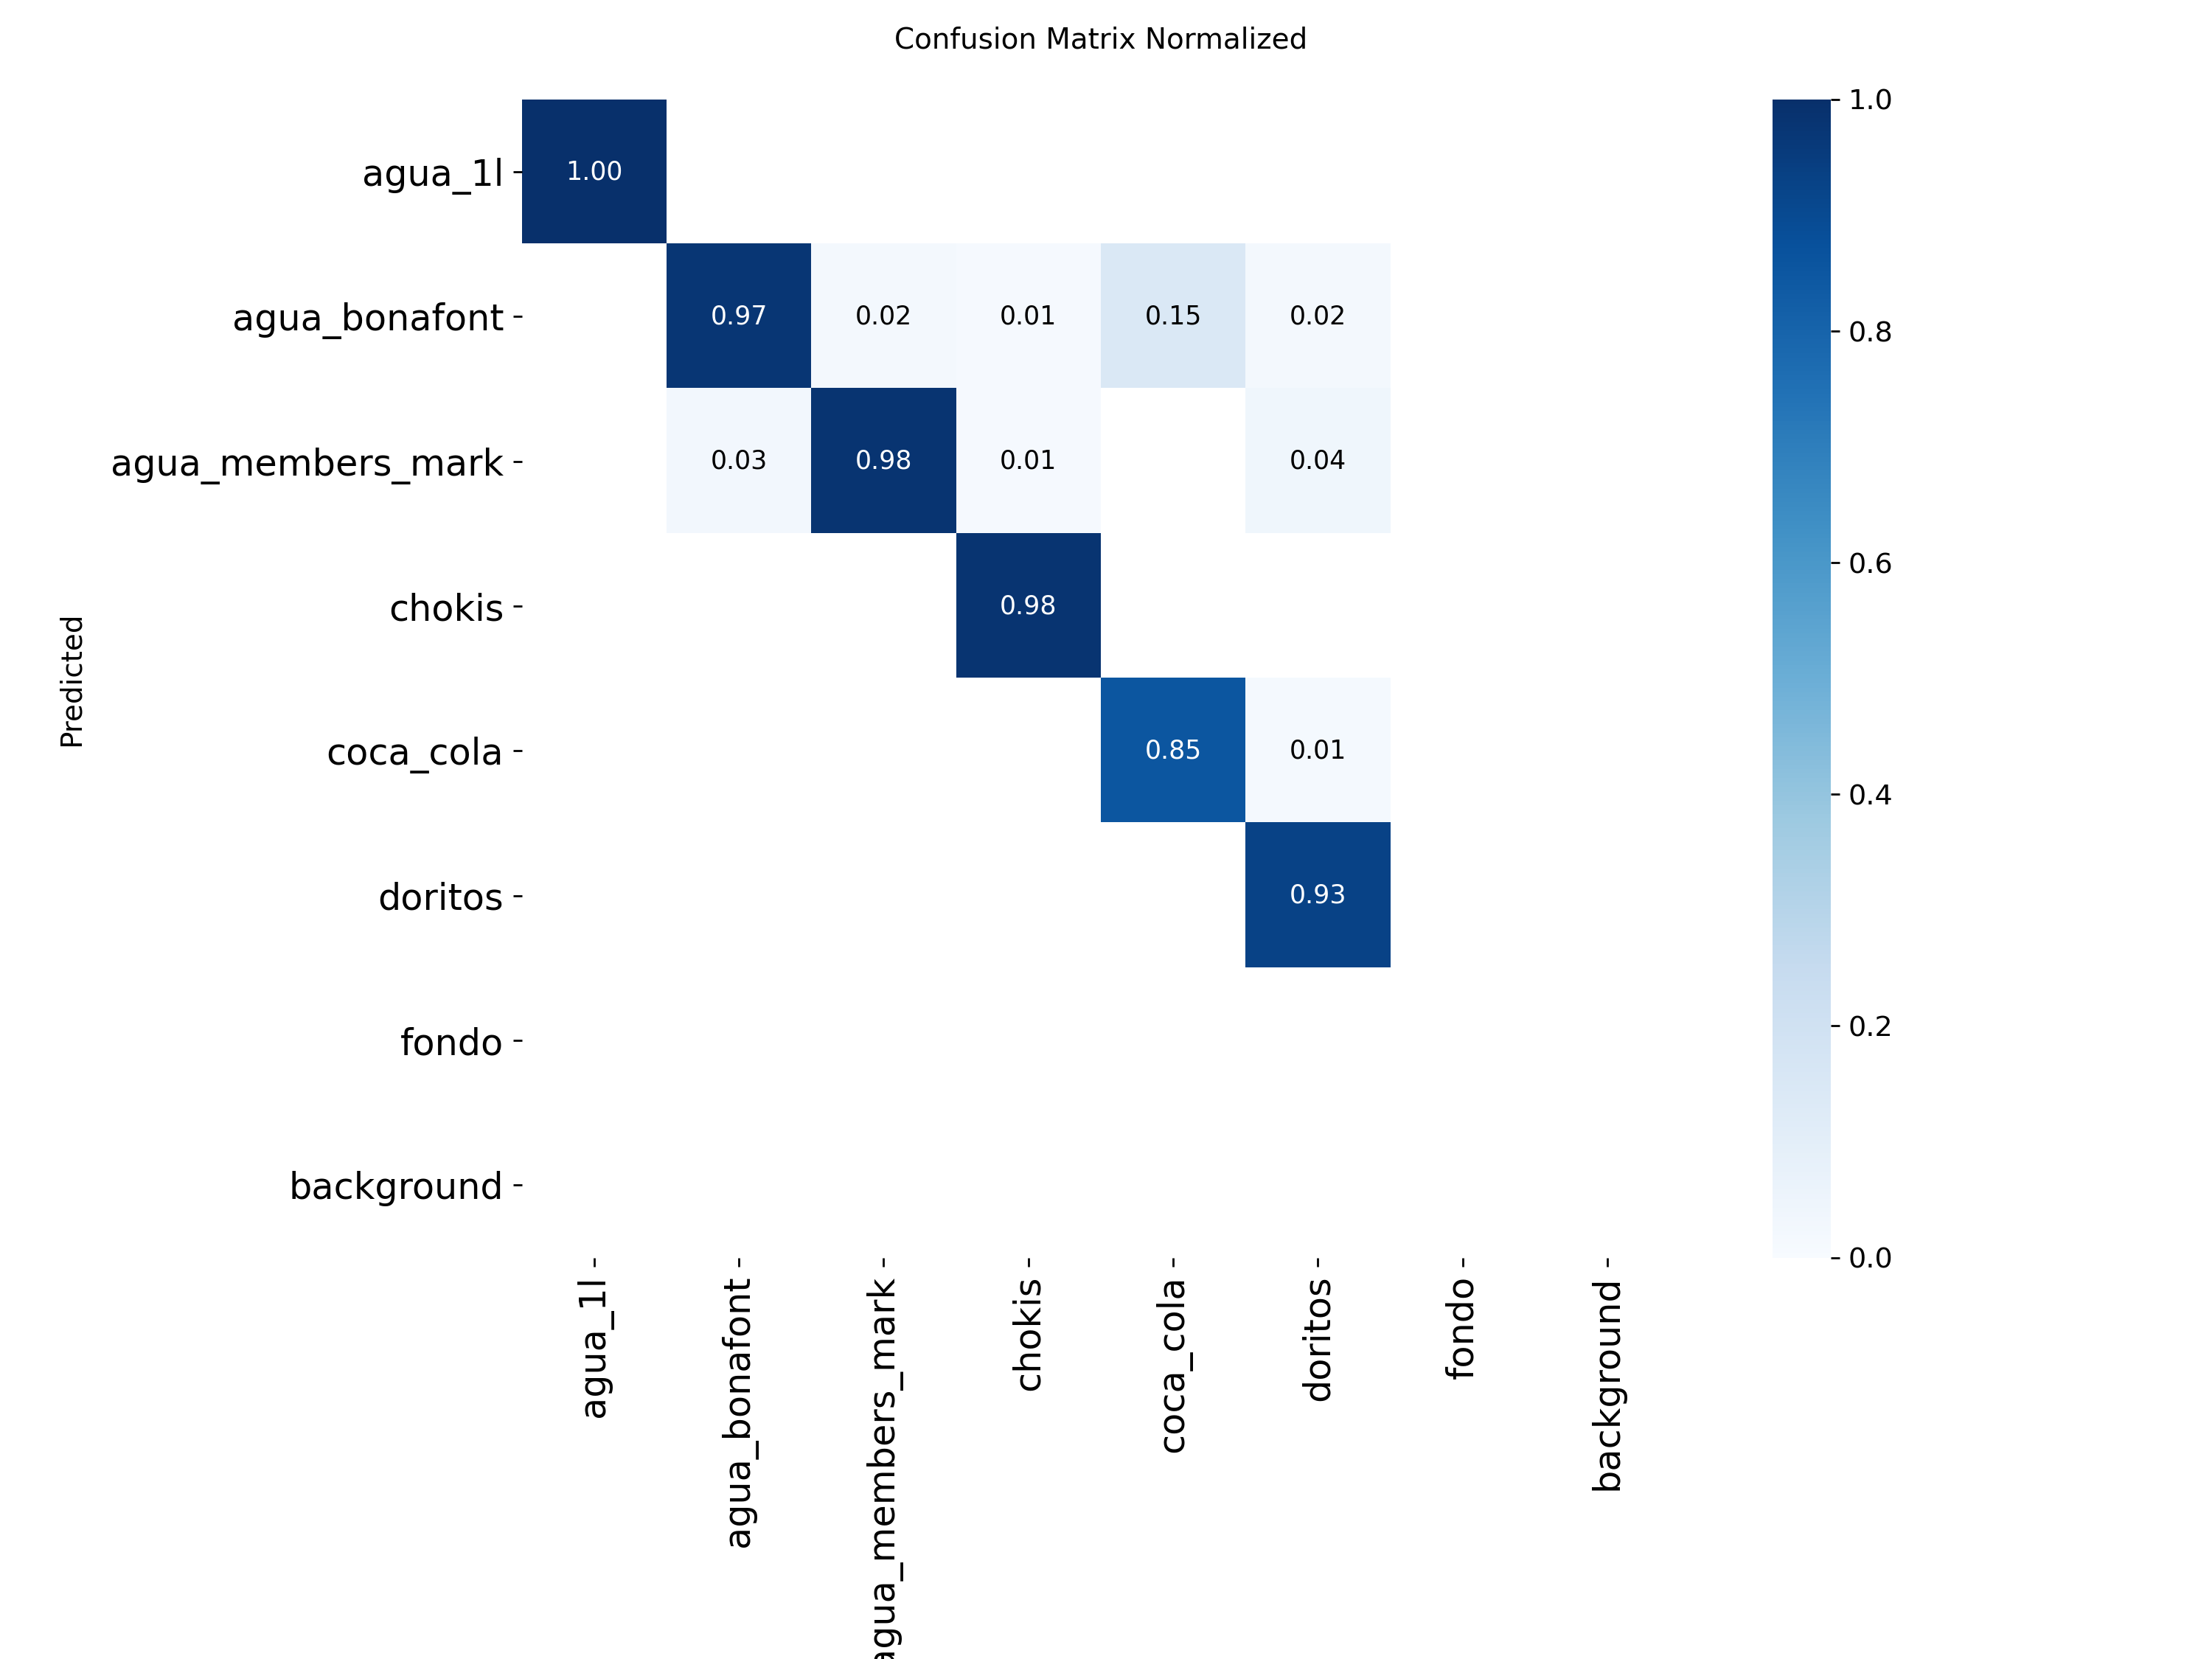

{
 "global": {
  "exactitud_top1": 0.9526,
  "exactitud_top5": 1.0
 },
 "umbral": {
  "umbral": 0.6,
  "fotos_aceptadas_sin_confirmar": "772/801",
  "exactitud_en_aceptadas": 0.9663,
  "fotos_que_piden_confirmacion": 29
 },
 "confusiones": {
  "coca_cola -> agua_bonafont": 14,
  "doritos -> agua_members_mark": 9,
  "doritos -> agua_bonafont": 4,
  "agua_bonafont -> agua_members_mark": 3,
  "doritos -> coca_cola": 3,
  "agua_members_mark -> agua_bonafont": 2,
  "chokis -> agua_members_mark": 1,
  "chokis -> agua_bonafont": 1,
  "doritos -> chokis": 1
 }
}


In [21]:
from IPython.display import Image, display
import os
p = "artefactos/v1/eval/val_test/confusion_matrix_normalized.png"
display(Image(p, width=650)) if os.path.exists(p) else print("Sin imagen de matriz (Ultralytics 8.3 no evalúa test sin 'fondo'); ver metricas.json")
import json; m = json.load(open("artefactos/v1/eval/metricas.json"))
print(json.dumps({"global": m["global"], "umbral": m["umbral_de_confianza"], "confusiones": m["confusiones_mas_frecuentes"]}, indent=1, ensure_ascii=False))

## 9. Exportar a ONNX (para el backend)

In [22]:
from ultralytics import YOLO
try:
    onnx = YOLO("artefactos/v1/best.pt").export(format="onnx", imgsz=224, simplify=True)
    shutil.copy2(onnx, "artefactos/v1/best.onnx"); print("ONNX:", onnx)
except Exception as e:
    print("ONNX falló (no bloquea):", e)

Ultralytics 8.3.253 🚀 Python-3.10.12 torch-2.5.1+cu121 CPU (Intel Xeon Platinum 8259CL CPU @ 2.50GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
YOLO11n-cls summary (fused): 47 layers, 1,534,991 parameters, 0 gradients, 3.2 GFLOPs

PyTorch: starting from 'artefactos/v1/best.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 7) (3.0 MB)
requirements: Ultralytics requirement ['onnxruntime-gpu'] not found, attempting AutoUpdate...
Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/300.5 MB ? eta -:--:--
   ━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/300.5 MB 237.0 MB/s eta 0:00:02
   ━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.9/300.5 MB 215.6 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━ 140.2/300.5 MB 233.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━ 191.9/300.5 MB 238.7 MB

## 10. Empaquetar y DESCARGAR
Descarga `artefactos_v1.zip` **y este notebook con salidas** (File → Download) antes de cerrar.

In [23]:
shutil.rmtree("artefactos/humo_dli", ignore_errors=True)
zipf = shutil.make_archive("/dli/task/artefactos_v1", "zip", "/dli/task/vision", "artefactos/v1")
print(zipf, os.path.getsize(zipf) // 1024, "KB")
from IPython.display import FileLink; display(FileLink(os.path.relpath(zipf, os.getcwd())))
print(open("artefactos/v1/registro.json").read()[:1200])

/dli/task/artefactos_v1.zip 17275 KB


/dli/task/artefactos_v1.zip

{
  "tarea": "clasificación de imágenes",
  "modelo_base": {
    "nombre": "YOLO11n-cls (clasificación)",
    "archivo": "yolo11n-cls.pt",
    "procedencia": "Ultralytics, preentrenado en ImageNet-1k (1000 clases) — https://docs.ultralytics.com/tasks/classify/",
    "licencia": "AGPL-3.0"
  },
  "datos": "/dli/task/vision/dataset",
  "clases": [
    "agua_1l",
    "agua_bonafont",
    "agua_members_mark",
    "chokis",
    "coca_cola",
    "doritos",
    "fondo"
  ],
  "parametros": {
    "data": "/dli/task/vision/dataset",
    "modelo": "yolo11n-cls.pt",
    "nombre": "v1",
    "epochs": 30,
    "imgsz": 224,
    "batch": 64,
    "patience": 10,
    "seed": 0,
    "fliplr": 0.5,
    "flipud": 0.0,
    "hsv_h": 0.04,
    "hsv_s": 0.7,
    "hsv_v": 0.5,
    "erasing": 0.3,
    "auto_augment": null
  },
  "inicio": "2026-11-20T11:11:01+00:00",
  "fin": "2026-11-20T11:15:32+00:00",
  "duracion_min": 4.5,
  "epocas_ejecutadas": 13,
  "mejor_fitness_val": 1.0,
  "entorno": {
    "python": "

In [24]:
import os, sys, runpy, torch, tensorrt
os.chdir("/dli/task/vision"); sys.path.insert(0, "/dli/task/vision")
torch.backends.cudnn.enabled = False
print("TensorRT", tensorrt.__version__, "| existe export_trt.py:", os.path.exists("export_trt.py"))
sys.argv = ["export_trt.py", "--nombre", "v1"]
runpy.run_path("export_trt.py", run_name="__main__")

TensorRT 10.7.0.post1 | existe export_trt.py: True
Ultralytics 8.3.253 🚀 Python-3.10.12 torch-2.5.1+cu121 CPU (Intel Xeon Platinum 8259CL CPU @ 2.50GHz)
YOLO11n-cls summary (fused): 47 layers, 1,534,991 parameters, 0 gradients, 3.2 GFLOPs

PyTorch: starting from '/dli/task/vision/artefactos/v1/best.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 7) (3.0 MB)

ONNX: starting export with onnx 1.23.2 opset 19...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 0.5s, saved as '/dli/task/vision/artefactos/v1/best.onnx' (5.9 MB)

Export complete (0.6s)
Results saved to /dli/task/vision/artefactos/v1
Predict:         yolo predict task=classify model=/dli/task/vision/artefactos/v1/best.onnx imgsz=224  
Validate:        yolo val task=classify model=/dli/task/vision/artefactos/v1/best.onnx imgsz=224 data=/dli/task/vision/dataset  
Visualize:       https://netron.app
Ultralytics 8.3.253 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla T4, 14930MiB)
YOLO11n-cls summa

{'__name__': '__main__',
 '__doc__': 'Optimización con NVIDIA TensorRT (bases §9: herramienta NVIDIA para optimizar/desplegar).\n\nExporta best.pt -> best.onnx -> best.engine (FP16) y compara PyTorch vs TensorRT con las MISMAS\nfotos de test: latencia, FPS y exactitud. Demuestra que la optimización acelera sin perder precisión.\n\nProduce en artefactos/<nombre>/:\n    best.onnx        formato intermedio (también sirve de respaldo en CPU con onnxruntime)\n    best.engine      motor TensorRT FP16 — es el que carga el backend en la demo\n    benchmark.json   tabla comparativa + SHA-256 de cada artefacto\n\nIMPORTANTE: un .engine solo corre en el mismo modelo de GPU y la misma versión de TensorRT con\nque se construyó (aquí: Tesla T4 del entorno DLI). Si cambian de GPU, regenerarlo desde best.onnx.\n\nUso:\n    python export_trt.py --nombre v1\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'export_trt.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'bu

In [25]:
import os, json, shutil
os.chdir("/dli/task")
print(sorted(os.listdir("vision/artefactos/v1")))
print(json.dumps(json.load(open("vision/artefactos/v1/benchmark.json")), indent=1, ensure_ascii=False)[:1500])
print(shutil.make_archive("/dli/task/artefactos_v1_trt", "zip", "/dli/task/vision", "artefactos/v1"))


['benchmark.json', 'best.engine', 'best.onnx', 'best.pt', 'estadisticas_datos.json', 'eval', 'registro.json', 'resultados']
{
 "fecha": "2026-11-20T11:31:59+00:00",
 "herramienta_nvidia": "TensorRT — compila el grafo ONNX a un motor optimizado para la GPU (fusión de capas, precisión FP16 con Tensor Cores, selección de kernels)",
 "entorno": {
  "python": "3.10.12",
  "so": "Linux-6.5.0-1014-aws-x86_64-with-glibc2.35",
  "torch": "2.5.1+cu121",
  "cudnn": "desactivado (SIN_CUDNN)",
  "cuda": "12.1",
  "gpu": "Tesla T4",
  "ultralytics": "8.3.253",
  "tensorrt": "10.7.0.post1",
  "nvidia_smi": "Tesla T4, 545.23.08, 15360 MiB"
 },
 "resultados": {
  "PyTorch FP32 (best.pt)": {
   "inferencia_ms_media": 8.76,
   "inferencia_ms_p95": 9.07,
   "total_ms_media": 12.29,
   "fps_inferencia": 114.1,
   "exactitud_top1": 0.9551,
   "fotos": 401
  },
  "TensorRT FP16 (best.engine)": {
   "inferencia_ms_media": 1.04,
   "inferencia_ms_p95": 1.05,
   "total_ms_media": 4.83,
   "fps_inferencia": 964.